# Отток клиентов: определить, измерить, предсказать

Директор по продуктам говорит: «Мы теряем клиентов. Нужна модель, которая покажет, кто уйдёт следующим».

В скоринге таргет можно было вывести из платежей: человек не заплатил, просрочка накопилась, событие произошло.
Здесь такого события нет. Клиент не расторгает договор, он просто перестаёт пользоваться картой.
Поэтому оттока в базе нет и быть не может, вы определяете его сами.

> **Это каркас, а не формат решения.** Здесь только подключение к базе и порядок шагов,
> чтобы вы не тратили время на старт. От дата-сайентиста ждут собственного хода работы:
> идите дальше и глубже, чем расписано ниже, проверяйте свои гипотезы, добавляйте свои
> разрезы и графики. Заполненные чужие ячейки решением не считаются.

## Данные

Postgres `academy_db`, схема `public`, таблицы с префиксом `churn_`. Данные по 31 декабря 2025 года.

Как и в прошлой выгрузке, сюда попало лишнее: старые копии, витрины неизвестного происхождения,
служебные таблицы. Что использовать, решаете сами и объясняете.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# ===== ПОДСТАВЬТЕ СВОИ ДАННЫЕ =====

engine = create_engine(DSN)

def q(sql):
    return pd.read_sql(sql, engine)

# Проверим, что таблицы доступны
tables = q("""
SELECT tablename 
FROM pg_tables 
WHERE schemaname = 'public' AND tablename LIKE 'churn_%%'
ORDER BY 1
""")
print(tables)

                     tablename
0             churn_app_events
1                  churn_cards
2              churn_customers
3          churn_customers_360
4      churn_customers_crm_old
5             churn_nps_survey
6         churn_product_events
7               churn_products
8    churn_retention_campaigns
9   churn_subscription_charges
10         churn_subscriptions
11       churn_support_tickets
12        churn_tariff_changes
13                  churn_temp
14          churn_transactions
15  churn_transactions_archive


## Блок 2. Очистка от будущих дат

In [3]:
txn_query = """
SELECT txn_id, customer_id, card_id, txn_ts, txn_type, 
       mcc_group, channel, amount_uzs, status
FROM churn_transactions
WHERE txn_ts <= '2025-12-31'
  AND status = 'approved'
"""
df_txn = q(txn_query)
print(f"Загружено {len(df_txn):,} транзакций (только approved)")
print(f"Период: {df_txn['txn_ts'].min()} – {df_txn['txn_ts'].max()}")
print(f"Уникальных клиентов: {df_txn['customer_id'].nunique():,}")

Загружено 1,692,460 транзакций (только approved)
Период: 2024-01-01 07:01:00 – 2025-12-30 23:59:00
Уникальных клиентов: 17,771


## Блок 3. Загрузка справочников и других таблиц (с фильтром будущего)

In [5]:
# Клиенты
df_cust = q("SELECT * FROM churn_customers")
print(f"Клиентов: {len(df_cust)}")

# Карты
df_cards = q("""
SELECT * FROM churn_cards 
WHERE issue_date <= '2025-12-31' 
  AND (expiry_date <= '2025-12-31' OR expiry_date IS NULL)
""")
print(f"Карт: {len(df_cards)}")

# События в приложении
df_app = q("""
SELECT * FROM churn_app_events 
WHERE event_ts <= '2025-12-31'
""")
print(f"Событий в приложении: {len(df_app):,}")

# Продуктовые события
df_prod_ev = q("""
SELECT * FROM churn_product_events 
WHERE event_date <= '2025-12-31'
""")
print(f"Продуктовых событий: {len(df_prod_ev):,}")

# Подписки
df_subs = q("""
SELECT * FROM churn_subscriptions 
WHERE started_at <= '2025-12-31' 
  AND (canceled_at <= '2025-12-31' OR canceled_at IS NULL)
""")
print(f"Подписок: {len(df_subs)}")

# Списания по подпискам
df_sub_charges = q("""
SELECT * FROM churn_subscription_charges 
WHERE charged_at <= '2025-12-31'
""")
print(f"Списаний: {len(df_sub_charges):,}")

# Изменения тарифа
df_tariff = q("""
SELECT * FROM churn_tariff_changes 
WHERE effective_date <= '2025-12-31'
""")
print(f"Изменений тарифа: {len(df_tariff)}")

# Обращения в поддержку
df_support = q("""
SELECT * FROM churn_support_tickets 
WHERE opened_at <= '2025-12-31' 
  AND (resolved_at <= '2025-12-31' OR resolved_at IS NULL)
""")
print(f"Обращений: {len(df_support)}")

# NPS
df_nps = q("SELECT * FROM churn_nps_survey WHERE survey_date <= '2025-12-31'")
print(f"NPS записей: {len(df_nps)}")

# Ретеншн-кампании
df_ret = q("SELECT * FROM churn_retention_campaigns WHERE contacted_at <= '2025-12-31'")
print(f"Кампаний: {len(df_ret)}")

# Продукты (открытые/закрытые)
df_prod = q("""
SELECT * FROM churn_products 
WHERE opened_at <= '2025-12-31' 
  AND (closed_at <= '2025-12-31' OR closed_at IS NULL)
""")
print(f"Записей о продуктах: {len(df_prod)}")

Клиентов: 20000
Карт: 711
Событий в приложении: 2,602,209
Продуктовых событий: 319,138
Подписок: 6334
Списаний: 80,857
Изменений тарифа: 8044
Обращений: 15923
NPS записей: 4600
Кампаний: 3305
Записей о продуктах: 47975


## Блок 4. Анализ пауз между транзакциями (выбор порога оттока)

Всего интервалов: 1,674,689


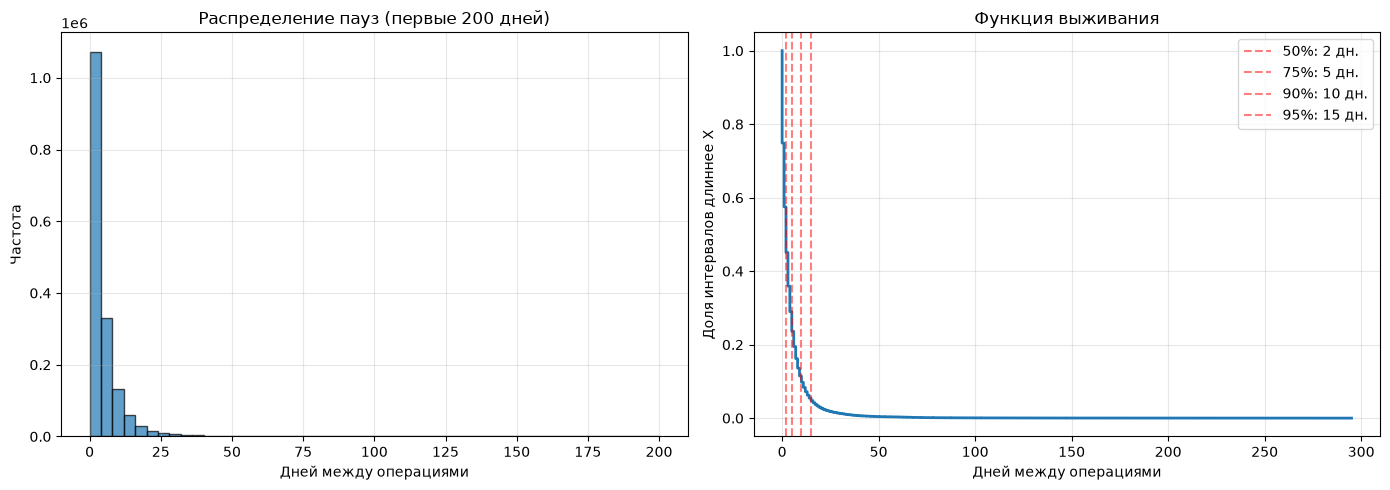

Статистика интервалов между операциями:
  Медиана: 2 дней
  75-й перцентиль: 5 дней
  90-й перцентиль: 10 дней
  95-й перцентиль: 15 дней
  99-й перцентиль: 34 дней


In [7]:
# Для каждого клиента вычисляем интервалы между последовательными транзакциями
# Сортируем по клиенту и дате
df_txn_sorted = df_txn.sort_values(['customer_id', 'txn_ts'])

# Группируем и вычисляем разницу в днях между соседними транзакциями
intervals = []
for cust, group in df_txn_sorted.groupby('customer_id'):
    if len(group) > 1:
        dates = group['txn_ts'].values
        diffs = np.diff(dates).astype('timedelta64[D]').astype(int)
        intervals.extend(diffs)
        
intervals = np.array(intervals)
print(f"Всего интервалов: {len(intervals):,}")

# Визуализация распределения
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма с логарифмической шкалой по X
axes[0].hist(intervals, bins=50, range=(0, 200), edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Дней между операциями')
axes[0].set_ylabel('Частота')
axes[0].set_title('Распределение пауз (первые 200 дней)')
axes[0].grid(True, alpha=0.3)

# Функция выживания (доля интервалов > X)
sorted_intervals = np.sort(intervals)
survival = 1 - np.arange(1, len(sorted_intervals)+1) / len(sorted_intervals)
axes[1].plot(sorted_intervals, survival, linewidth=2)
axes[1].set_xlabel('Дней между операциями')
axes[1].set_ylabel('Доля интервалов длиннее X')
axes[1].set_title('Функция выживания')
axes[1].grid(True, alpha=0.3)
# Отметим важные квантили
for p in [0.5, 0.75, 0.9, 0.95]:
    val = np.percentile(intervals, p*100)
    axes[1].axvline(val, linestyle='--', color='red', alpha=0.5, label=f'{p:.0%}: {val:.0f} дн.')
axes[1].legend()

plt.tight_layout()
plt.show()

# Выведем ключевые статистики
print("Статистика интервалов между операциями:")
print(f"  Медиана: {np.median(intervals):.0f} дней")
print(f"  75-й перцентиль: {np.percentile(intervals, 75):.0f} дней")
print(f"  90-й перцентиль: {np.percentile(intervals, 90):.0f} дней")
print(f"  95-й перцентиль: {np.percentile(intervals, 95):.0f} дней")
print(f"  99-й перцентиль: {np.percentile(intervals, 99):.0f} дней")

## Блок 5. Формирование обучающей выборки (снэпшот, таргет, исключения)

In [8]:
# Параметры
T = 58          # дней тишины = отток (выберите на основе анализа)
S = pd.Timestamp('2025-12-01')
H = 30          # горизонт прогноза

# Приведём signup_date к datetime для корректного сравнения
df_cust['signup_date'] = pd.to_datetime(df_cust['signup_date'])



# Определим клиентов, активных на снэпшот (последняя транзакция не ранее S-T)
last_txn_before_S = df_txn[df_txn['txn_ts'] <= S].groupby('customer_id')['txn_ts'].max().reset_index()
last_txn_before_S.columns = ['customer_id', 'last_txn_date']

active_at_S = last_txn_before_S[last_txn_before_S['last_txn_date'] >= (S - timedelta(days=T))]

# Исключаем клиентов, зарегистрированных после S
cust_signup = df_cust[['customer_id', 'signup_date']].copy()
cust_signup = cust_signup[cust_signup['signup_date'] <= S]

# Объединяем
base = active_at_S.merge(cust_signup, on='customer_id', how='inner')
print(f"Клиентов, активных на снэпшот: {len(base)}")

# Проверим, сколько клиентов имеют последнюю транзакцию очень давно (для понимания)
base['days_since_last'] = (S - base['last_txn_date']).dt.days
print("Распределение дней с последней операции до снэпшота:")
print(base['days_since_last'].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

# Определяем таргет: были ли транзакции в (S, S+H]
txn_in_horizon = df_txn[(df_txn['txn_ts'] > S) & (df_txn['txn_ts'] <= S + timedelta(days=H))]
txn_in_horizon = txn_in_horizon.groupby('customer_id').size().reset_index(name='cnt_in_horizon')

base = base.merge(txn_in_horizon, on='customer_id', how='left')
base['cnt_in_horizon'] = base['cnt_in_horizon'].fillna(0)
base['target'] = (base['cnt_in_horizon'] == 0).astype(int)

print(f"Итоговый размер выборки: {len(base)}")
print(f"Доля оттока: {base['target'].mean():.2%}")

# Посмотрим, сколько клиентов попало в отток
print(f"Количество отточных клиентов: {base['target'].sum()}")

Клиентов, активных на снэпшот: 13189
Распределение дней с последней операции до снэпшота:
count    13189.000000
mean         7.238153
std          9.898143
min          0.000000
50%          3.000000
75%          9.000000
90%         21.000000
95%         31.000000
99%         45.000000
max         57.000000
Name: days_since_last, dtype: float64
Итоговый размер выборки: 13189
Доля оттока: 8.96%
Количество отточных клиентов: 1182


## Блок 6 (исправленный): динамика оттока по месяцам

    snapshot  n_clients  churn_rate
0 2025-06-01      12346    0.104487
1 2025-07-01      12622    0.138092
2 2025-08-01      12771    0.141962
3 2025-09-01      12724    0.118752
4 2025-10-01      12817    0.108762
5 2025-11-01      13027    0.101251


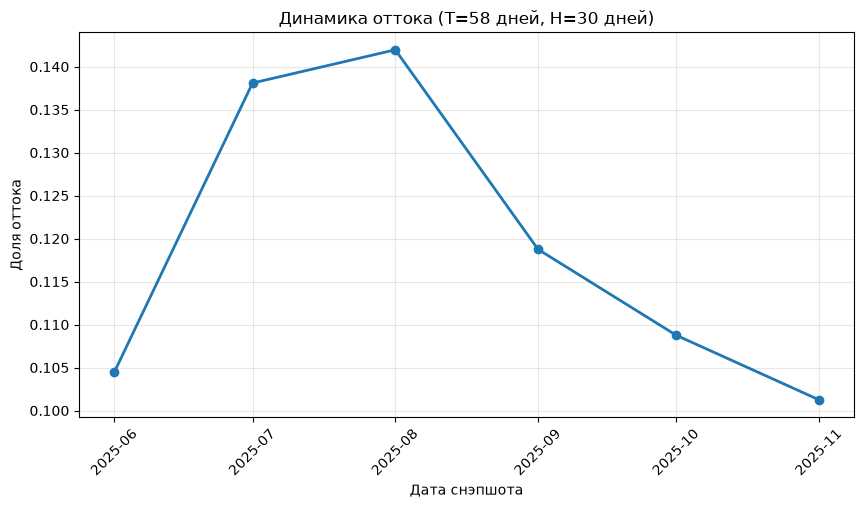

In [9]:
months = pd.date_range('2025-06-01', '2025-11-01', freq='MS')
results = []

for month_start in months:
    S_local = month_start
    # Последняя транзакция до S_local
    last_txn = df_txn[df_txn['txn_ts'] <= S_local].groupby('customer_id')['txn_ts'].max().reset_index()
    last_txn.columns = ['customer_id', 'last_txn_date']
    active = last_txn[last_txn['last_txn_date'] >= (S_local - timedelta(days=T))]
    active = active.merge(cust_signup, on='customer_id', how='inner')
    # Транзакции в горизонте
    txn_hor = df_txn[(df_txn['txn_ts'] > S_local) & (df_txn['txn_ts'] <= S_local + timedelta(days=H))]
    txn_hor = txn_hor.groupby('customer_id').size().reset_index(name='cnt')
    active = active.merge(txn_hor, on='customer_id', how='left')
    active['cnt'] = active['cnt'].fillna(0)
    active['target'] = (active['cnt'] == 0).astype(int)
    
    results.append({
        'snapshot': S_local,
        'n_clients': len(active),
        'churn_rate': active['target'].mean()
    })

df_dynamics = pd.DataFrame(results)
print(df_dynamics)

plt.figure(figsize=(10,5))
plt.plot(df_dynamics['snapshot'], df_dynamics['churn_rate'], marker='o', linewidth=2)
plt.title(f'Динамика оттока (T={T} дней, H={H} дней)')
plt.xlabel('Дата снэпшота')
plt.ylabel('Доля оттока')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.show()

## Полный код для построения фич, модели и оценки

Строим выборки...
Train: 12828 клиентов, доля оттока 10.92%
Val:   13038 клиентов, доля оттока 10.15%
Test:  13196 клиентов, доля оттока 8.97%
Количество фич: 61
Модель обучена!
Метрики:
Train ROC-AUC: 0.8211, PR-AUC: 0.4455
Val   ROC-AUC: 0.7207, PR-AUC: 0.3256
Test  ROC-AUC: 0.6954, PR-AUC: 0.2785 (декабрь, out-of-sample)
Recall@10% (Val):  36.21% (ловим 36.21% оттоков в топ-10%)
Recall@10% (Test): 36.74% (ловим 36.74% оттоков в топ-10%)

Топ-10 самых важных фичей:
           feature  importance
11   txn_cnt_w_30d    0.167382
14  txn_days_w_30d    0.136741
44     mcc_cnt_30d    0.116236
15   txn_mcc_w_30d    0.103307
49  app_events_30d    0.028492
12   txn_sum_w_30d    0.023388
16   txn_cnt_w_60d    0.019336
48      card_types    0.018228
47      card_count    0.016851
19  txn_days_w_60d    0.016530


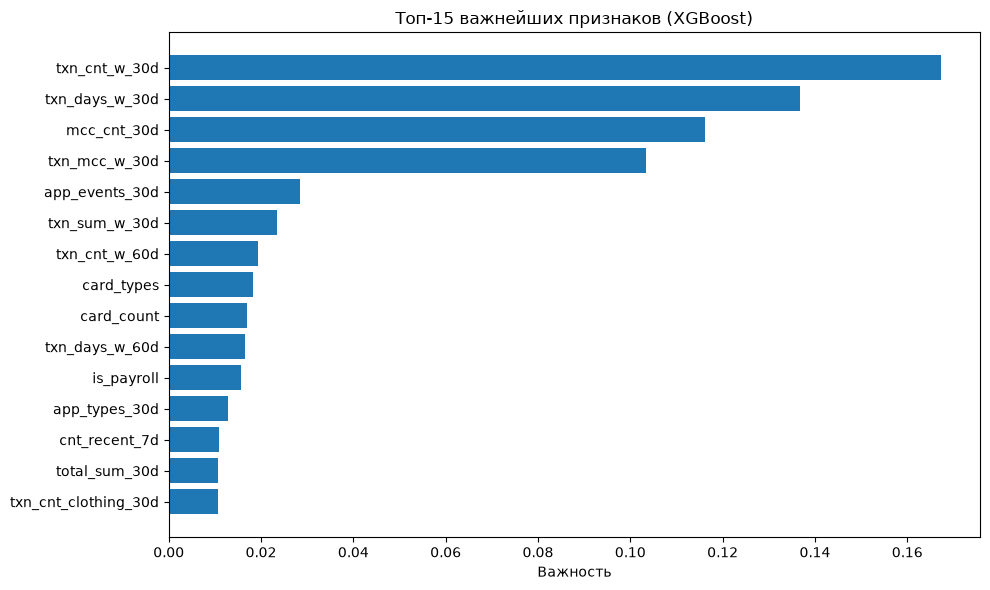

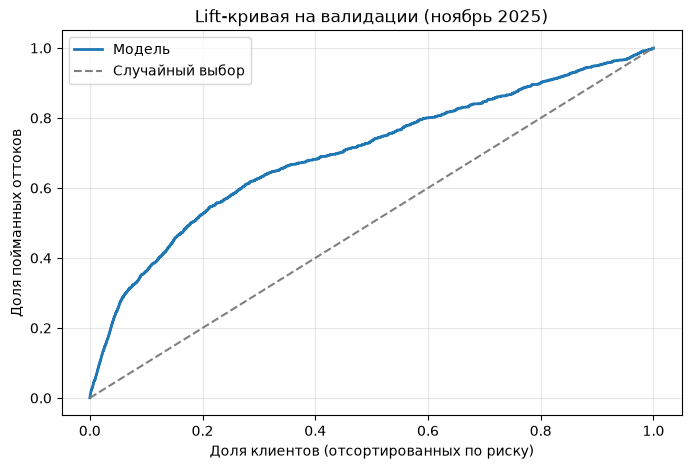

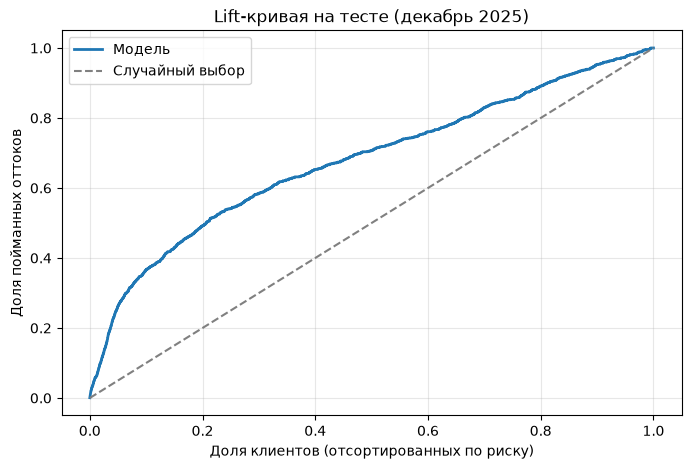


Топ-20 клиентов с самым высоким риском оттока в декабре 2025:
       customer_id  prob_churn  target  days_since_last
6587          9939    0.681175       1               39
3115          4718    0.679122       1               34
7219         10874    0.679122       1               30
2778          4206    0.679122       1               37
2240          3387    0.679122       1               32
11439        17338    0.679122       1               43
1871          2833    0.679122       1               40
12932        19627    0.679122       1               35
1213          1844    0.679122       1               31
3509          5296    0.679122       1               47
6626          9992    0.679122       1               38
10940        16571    0.678783       1               40
9722         14672    0.676723       1               38
3179          4819    0.676723       1               45
10280        15545    0.676607       1               33
4048          6118    0.676607       1   

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 1. Функция для построения базы (клиенты + таргет) для любого снэпшота
# ============================================================
def get_base(snapshot_date, T=60, H=30):
    S = pd.Timestamp(snapshot_date)
    
    # Приводим signup_date к Timestamp, чтобы избежать ошибок сравнения
    df_cust_local = df_cust.copy()
    df_cust_local['signup_date'] = pd.to_datetime(df_cust_local['signup_date'])
    
    # Последняя транзакция до снэпшота
    last_txn = df_txn[df_txn['txn_ts'] <= S].groupby('customer_id')['txn_ts'].max().reset_index()
    last_txn.columns = ['customer_id', 'last_txn_date']
    
    # Активные на снэпшот (последняя операция не ранее S - T)
    active = last_txn[last_txn['last_txn_date'] >= (S - timedelta(days=T))]
    
    # Исключаем клиентов, зарегистрированных после S
    cust_valid = df_cust_local[df_cust_local['signup_date'] <= S]
    active = active.merge(cust_valid[['customer_id']], on='customer_id', how='inner')
    
    # Транзакции в горизонте (S, S+H]
    txn_hor = df_txn[(df_txn['txn_ts'] > S) & (df_txn['txn_ts'] <= S + timedelta(days=H))]
    txn_hor = txn_hor.groupby('customer_id').size().reset_index(name='cnt_horizon')
    
    base = active.merge(txn_hor, on='customer_id', how='left')
    base['cnt_horizon'] = base['cnt_horizon'].fillna(0)
    base['target'] = (base['cnt_horizon'] == 0).astype(int)
    
    base['snapshot_date'] = S
    base['days_since_last'] = (S - base['last_txn_date']).dt.days
    
    return base

# ============================================================
# 2. Функция для добавления признаков (фич) к базе
# ============================================================

def add_features(base, S):
    """
    Добавляет все признаки к базе, используя данные строго до даты S
    """
    df = base.copy()
    S = pd.Timestamp(S)
    
    # ---- Приводим все даты к Timestamp ----
    # Копируем таблицы, чтобы не менять глобальные переменные
    df_cards_local = df_cards.copy()
    df_cards_local['issue_date'] = pd.to_datetime(df_cards_local['issue_date'])
    df_cards_local['expiry_date'] = pd.to_datetime(df_cards_local['expiry_date'])
    
    df_app_local = df_app.copy()
    df_app_local['event_ts'] = pd.to_datetime(df_app_local['event_ts'])
    
    df_support_local = df_support.copy()
    df_support_local['opened_at'] = pd.to_datetime(df_support_local['opened_at'])
    
    df_tariff_local = df_tariff.copy()
    df_tariff_local['effective_date'] = pd.to_datetime(df_tariff_local['effective_date'])
    
    df_nps_local = df_nps.copy()
    df_nps_local['survey_date'] = pd.to_datetime(df_nps_local['survey_date'])
    
    df_ret_local = df_ret.copy()
    df_ret_local['contacted_at'] = pd.to_datetime(df_ret_local['contacted_at'])
    
    # ---- 2.1. Транзакционные фичи ----
    windows = [7, 14, 30, 60]
    for w in windows:
        txn_w = df_txn[(df_txn['txn_ts'] <= S) & (df_txn['txn_ts'] > S - timedelta(days=w))]
        agg = txn_w.groupby('customer_id').agg(
            txn_cnt_w=('txn_id', 'count'),
            txn_sum_w=('amount_uzs', 'sum'),
            txn_avg_w=('amount_uzs', 'mean'),
            txn_days_w=('txn_ts', lambda x: x.dt.date.nunique()),
            txn_mcc_w=('mcc_group', 'nunique')
        ).reset_index()
        agg.columns = ['customer_id'] + [f'{col}_{w}d' for col in agg.columns[1:]]
        df = df.merge(agg, on='customer_id', how='left')
    
    # Динамика: последние 7 дней против предыдущих 7
    txn_recent = df_txn[(df_txn['txn_ts'] <= S) & (df_txn['txn_ts'] > S - timedelta(days=7))]
    txn_prev = df_txn[(df_txn['txn_ts'] <= S - timedelta(days=7)) & (df_txn['txn_ts'] > S - timedelta(days=14))]
    
    recent_cnt = txn_recent.groupby('customer_id').size().reset_index(name='cnt_recent_7d')
    prev_cnt = txn_prev.groupby('customer_id').size().reset_index(name='cnt_prev_7d')
    df = df.merge(recent_cnt, on='customer_id', how='left')
    df = df.merge(prev_cnt, on='customer_id', how='left')
    df['cnt_recent_7d'] = df['cnt_recent_7d'].fillna(0)
    df['cnt_prev_7d'] = df['cnt_prev_7d'].fillna(0)
    df['dyn_7d_vs_prev'] = (df['cnt_recent_7d'] - df['cnt_prev_7d']) / (df['cnt_prev_7d'] + 1)


    # ---- 2.1.5. Дополнительные MCC-фичи ----
    S_dt = S  # уже есть

    # 1. Количество операций по каждой категории за последние 30 дней (можно только для топ-категорий, но для демонстрации возьмём все)
    for cat in ['grocery', 'restaurants', 'fuel', 'entertainment', 'clothing', 'electronics', 'transport', 'pharmacy']:
        txn_cat = df_txn[
            (df_txn['txn_ts'] <= S_dt) & 
            (df_txn['txn_ts'] > S_dt - timedelta(days=30)) &
            (df_txn['mcc_group'] == cat)
        ]
        agg = txn_cat.groupby('customer_id').agg(
            **{f'txn_cnt_{cat}_30d': ('txn_id', 'count'),
            f'txn_sum_{cat}_30d': ('amount_uzs', 'sum')}
        ).reset_index()
        df = df.merge(agg, on='customer_id', how='left')

    # 2. Доля дискреционных трат (как описано выше)
    discretionary = ['restaurants', 'entertainment', 'clothing', 'electronics']
    txn_30_all = df_txn[(df_txn['txn_ts'] <= S_dt) & (df_txn['txn_ts'] > S_dt - timedelta(days=30))]
    total_sum = txn_30_all.groupby('customer_id')['amount_uzs'].sum().reset_index(name='total_sum_30d')
    disc_sum = txn_30_all[txn_30_all['mcc_group'].isin(discretionary)].groupby('customer_id')['amount_uzs'].sum().reset_index(name='disc_sum_30d')
    df = df.merge(total_sum, on='customer_id', how='left')
    df = df.merge(disc_sum, on='customer_id', how='left')
    df['disc_share_30d'] = df['disc_sum_30d'] / (df['total_sum_30d'] + 1)

    # 3. Наличие зарплатных поступлений (income) за последние 90 дней
    income_90 = df_txn[(df_txn['txn_ts'] <= S_dt) & (df_txn['txn_ts'] > S_dt - timedelta(days=90)) & (df_txn['mcc_group'] == 'income')]
    income_clients = income_90['customer_id'].unique()
    df['has_income_90d'] = df['customer_id'].isin(income_clients).astype(int)

    # 4. Изменение разнообразия MCC по сравнению с предыдущим периодом
    mcc_30 = df_txn[(df_txn['txn_ts'] <= S_dt) & (df_txn['txn_ts'] > S_dt - timedelta(days=30))]
    mcc_prev = df_txn[(df_txn['txn_ts'] <= S_dt - timedelta(days=30)) & (df_txn['txn_ts'] > S_dt - timedelta(days=60))]
    mcc_30_agg = mcc_30.groupby('customer_id')['mcc_group'].nunique().reset_index(name='mcc_cnt_30d')
    mcc_prev_agg = mcc_prev.groupby('customer_id')['mcc_group'].nunique().reset_index(name='mcc_cnt_prev_30d')
    df = df.merge(mcc_30_agg, on='customer_id', how='left')
    df = df.merge(mcc_prev_agg, on='customer_id', how='left')
    df['mcc_cnt_change'] = df['mcc_cnt_30d'] - df['mcc_cnt_prev_30d']
    
    # ---- 2.2. Фичи по картам ----
    cards_active = df_cards_local[
        (df_cards_local['issue_date'] <= S) & 
        ((df_cards_local['expiry_date'] > S) | (df_cards_local['expiry_date'].isna()))
    ]
    cards_agg = cards_active.groupby('customer_id').agg(
        card_count=('card_id', 'count'),
        card_types=('card_type', 'nunique')
    ).reset_index()
    df = df.merge(cards_agg, on='customer_id', how='left')
    
    # ---- 2.3. Фичи по событиям в приложении ----
    app = df_app_local[
        (df_app_local['event_ts'] <= S) & 
        (df_app_local['event_ts'] > S - timedelta(days=30))
    ]
    app_agg = app.groupby('customer_id').agg(
        app_events_30d=('event_id', 'count'),
        app_types_30d=('event_type', 'nunique')
    ).reset_index()
    df = df.merge(app_agg, on='customer_id', how='left')
    
    # ---- 2.4. Фичи по поддержке ----
    support = df_support_local[
        (df_support_local['opened_at'] <= S) & 
        (df_support_local['opened_at'] > S - timedelta(days=90))
    ]
    support_agg = support.groupby('customer_id').agg(
        support_tickets_90d=('ticket_id', 'count')
    ).reset_index()
    df = df.merge(support_agg, on='customer_id', how='left')
    
    # ---- 2.5. Фичи по изменениям тарифа ----
    tariff = df_tariff_local[
        (df_tariff_local['effective_date'] <= S) & 
        (df_tariff_local['effective_date'] > S - timedelta(days=90))
    ]
    tariff_agg = tariff.groupby('customer_id').agg(
        tariff_changes_90d=('change_id', 'count')
    ).reset_index()
    df = df.merge(tariff_agg, on='customer_id', how='left')
    
    # ---- 2.6. Фичи по NPS ----
    nps_last = df_nps_local[df_nps_local['survey_date'] <= S].sort_values('survey_date').drop_duplicates('customer_id', keep='last')
    nps_last = nps_last[['customer_id', 'nps_score']].rename(columns={'nps_score': 'last_nps'})
    df = df.merge(nps_last, on='customer_id', how='left')
    
    # ---- 2.7. Фичи по ретеншн-кампаниям ----
    ret = df_ret_local[
        (df_ret_local['contacted_at'] <= S) & 
        (df_ret_local['contacted_at'] > S - timedelta(days=90))
    ]
    ret_agg = ret.groupby('customer_id').agg(
        retention_contacts_90d=('campaign_row_id', 'count'),
        retention_responded=('responded', 'sum')
    ).reset_index()
    df = df.merge(ret_agg, on='customer_id', how='left')
    
    # ---- 2.8. Демографические фичи ----
    cust_feat = df_cust[['customer_id', 'birth_date', 'region', 'segment', 'is_payroll', 'declared_income_uzs']].copy()
    cust_feat['birth_date'] = pd.to_datetime(cust_feat['birth_date'])
    cust_feat['age'] = (S - cust_feat['birth_date']).dt.days // 365
    # Заполним пропуски в доходе медианой
    median_income = cust_feat['declared_income_uzs'].median()
    cust_feat['declared_income_uzs'] = cust_feat['declared_income_uzs'].fillna(median_income)
    
    df = df.merge(cust_feat, on='customer_id', how='left')
    
    # ---- 2.9. Заполняем все NaN (для клиентов, у которых не было событий) ----
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if col not in ['customer_id', 'target', 'days_since_last', 'age']:
            if 'avg' in col or 'dyn' in col or 'age' in col:
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(0)
    
    return df

# ============================================================
# 3. Строим выборки для обучения, валидации и финального прогноза
# ============================================================
print("Строим выборки...")
S_train = '2025-10-01'
S_val = '2025-11-01'
S_test = '2025-12-01'

# База
base_train = get_base(S_train)
base_val = get_base(S_val)
base_test = get_base(S_test)

# Добавляем фичи
df_train = add_features(base_train, pd.Timestamp(S_train))
df_val = add_features(base_val, pd.Timestamp(S_val))
df_test = add_features(base_test, pd.Timestamp(S_test))

print(f"Train: {len(df_train)} клиентов, доля оттока {df_train['target'].mean():.2%}")
print(f"Val:   {len(df_val)} клиентов, доля оттока {df_val['target'].mean():.2%}")
print(f"Test:  {len(df_test)} клиентов, доля оттока {df_test['target'].mean():.2%}")

# ============================================================
# 4. Подготовка данных для XGBoost
# ============================================================
# Определим список фич (исключаем ID, даты, таргет)
exclude_cols = ['customer_id', 'snapshot_date', 'last_txn_date', 'target', 
                'cnt_horizon', 'birth_date', 'signup_date']
feature_cols = [col for col in df_train.columns if col not in exclude_cols]

# Для категориальных признаков сделаем one-hot (или можно оставить как есть, если XGBoost умеет)
# Я сделаю простой LabelEncoder для региона и сегмента
from sklearn.preprocessing import LabelEncoder
for col in ['region', 'segment']:
    le = LabelEncoder()
    # Обучаем на train, преобразуем все
    df_train[col] = le.fit_transform(df_train[col].astype(str))
    df_val[col] = le.transform(df_val[col].astype(str))
    df_test[col] = le.transform(df_test[col].astype(str))

X_train = df_train[feature_cols]
y_train = df_train['target']
X_val = df_val[feature_cols]
y_val = df_val['target']
X_test = df_test[feature_cols]
y_test = df_test['target']  # реальный таргет для оценки, но мы его не используем для обучения

print(f"Количество фич: {X_train.shape[1]}")

# ============================================================
# 5. Обучение модели XGBoost с out-of-time валидацией
# ============================================================
model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42,
    eval_metric='auc',
    early_stopping_rounds=30,   # перенесли в конструктор
    use_label_encoder=False,
    verbosity=0
)

# Обучаем (eval_set передаём в fit, early_stopping уже в конструкторе)
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

print("Модель обучена!")

# ============================================================
# 6. Оценка качества
# ============================================================
y_pred_train = model.predict_proba(X_train)[:, 1]
y_pred_val = model.predict_proba(X_val)[:, 1]
y_pred_test = model.predict_proba(X_test)[:, 1]

roc_train = roc_auc_score(y_train, y_pred_train)
roc_val = roc_auc_score(y_val, y_pred_val)
roc_test = roc_auc_score(y_test, y_pred_test)

pr_train = average_precision_score(y_train, y_pred_train)
pr_val = average_precision_score(y_val, y_pred_val)
pr_test = average_precision_score(y_test, y_pred_test)

print("="*50)
print("Метрики:")
print(f"Train ROC-AUC: {roc_train:.4f}, PR-AUC: {pr_train:.4f}")
print(f"Val   ROC-AUC: {roc_val:.4f}, PR-AUC: {pr_val:.4f}")
print(f"Test  ROC-AUC: {roc_test:.4f}, PR-AUC: {pr_test:.4f} (декабрь, out-of-sample)")

# Метрика Recall@k (топ 10% самых рискованных)
def recall_at_k(y_true, y_pred, k=0.1):
    n = int(len(y_true) * k)
    top_k_idx = np.argsort(y_pred)[-n:]
    return y_true.iloc[top_k_idx].sum() / y_true.sum()

recall_10_val = recall_at_k(y_val, y_pred_val, 0.1)
recall_10_test = recall_at_k(y_test, y_pred_test, 0.1)
print(f"Recall@10% (Val):  {recall_10_val:.2%} (ловим {recall_10_val:.2%} оттоков в топ-10%)")
print(f"Recall@10% (Test): {recall_10_test:.2%} (ловим {recall_10_test:.2%} оттоков в топ-10%)")

# ============================================================
# 7. Важность фичей
# ============================================================
importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nТоп-10 самых важных фичей:")
print(importance.head(10))

# Визуализация важности
plt.figure(figsize=(10, 6))
plt.barh(importance.head(15)['feature'], importance.head(15)['importance'])
plt.xlabel('Важность')
plt.title('Топ-15 важнейших признаков (XGBoost)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ============================================================
# 8. Lift-кривая (для бизнес-презентации)
# ============================================================
def plot_lift_curve(y_true, y_pred, title="Lift Curve"):
    data = pd.DataFrame({'y_true': y_true, 'y_pred': y_pred})
    data = data.sort_values('y_pred', ascending=False)
    data['cum_churn'] = data['y_true'].cumsum()
    data['cum_frac'] = np.arange(1, len(data)+1) / len(data)
    total_churn = data['y_true'].sum()
    
    plt.figure(figsize=(8, 5))
    plt.plot(data['cum_frac'], data['cum_churn'] / total_churn, linewidth=2, label='Модель')
    plt.plot([0, 1], [0, 1], '--', label='Случайный выбор', color='gray')
    plt.xlabel('Доля клиентов (отсортированных по риску)')
    plt.ylabel('Доля пойманных оттоков')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Строим lift-кривую для валидации (ноябрь)
plot_lift_curve(y_val, y_pred_val, "Lift-кривая на валидации (ноябрь 2025)")

# Строим lift-кривую для теста (декабрь)
plot_lift_curve(y_test, y_pred_test, "Lift-кривая на тесте (декабрь 2025)")

# ============================================================
# 9. Финальный скоринг: список клиентов с высоким риском в декабре
# ============================================================
# Добавляем предсказанные вероятности в датафрейм test
df_test['prob_churn'] = y_pred_test
df_test_sorted = df_test.sort_values('prob_churn', ascending=False)

# Выводим топ-20 клиентов с самым высоким риском уйти в декабре
print("\nТоп-20 клиентов с самым высоким риском оттока в декабре 2025:")
print(df_test_sorted[['customer_id', 'prob_churn', 'target', 'days_since_last']].head(20))

# Рекомендация: кому предлагать удержание?
# Предположим, бюджет позволяет обработать топ-10% клиентов
top_k = int(0.1 * len(df_test_sorted))
high_risk_clients = df_test_sorted.head(top_k)['customer_id'].tolist()
print(f"\nДля удержания рекомендуем {len(high_risk_clients)} клиентов (топ-10% по вероятности оттока).")
print(f"В этом списке реально ушло {df_test_sorted.head(top_k)['target'].sum()} клиентов из {df_test['target'].sum()} всех отточных.")
print(f"Это покрывает {df_test_sorted.head(top_k)['target'].sum() / df_test['target'].sum():.1%} всех оттоков декабря.")


In [ ]:
# ============================================================
# SHAP-объяснение: какие фичи двигают риск оттока
# ============================================================
import shap

# Explainer на основе обученной XGBoost-модели
explainer = shap.TreeExplainer(model)

# SHAP-значения для всей тестовой выборки
shap_values_all = explainer.shap_values(X_test)
# Страховка: некоторые версии SHAP возвращают список значений по классам
if isinstance(shap_values_all, list):
    shap_values_all = shap_values_all[1]  # вклад в класс 1 (отток)
shap_values_all = np.asarray(shap_values_all)

shap_df_all = pd.DataFrame(shap_values_all, columns=feature_cols, index=X_test.index)

# Для каждого клиента находим фичу с максимальным положительным вкладом (увеличивает риск)
top_feature_per_customer = shap_df_all.idxmax(axis=1)
top_value_per_customer = shap_df_all.max(axis=1)

# Добавляем в df_test
df_test['risk_driver'] = top_feature_per_customer.values
df_test['driver_value'] = top_value_per_customer.values

# Общие драйверы оттока: топ фич по среднему абсолютному SHAP-вкладу
print("Топ-10 фич по среднему абсолютному SHAP-вкладу:")
print(shap_df_all.abs().mean().sort_values(ascending=False).head(10))

# ============================================================
# Рекомендации по действию на основе главного драйвера риска
# ============================================================
def get_action(row):
    driver = row['risk_driver']
    if driver in ['txn_cnt_w_30d', 'txn_cnt_w_14d', 'txn_sum_w_30d']:
        return 'Предложить кешбэк/акцию'
    elif driver in ['app_events_30d', 'app_types_30d']:
        return 'Отправить пуш/SMS напоминание'
    elif driver in ['support_tickets_90d']:
        return 'Звонок оператора'
    elif driver in ['tariff_changes_90d']:
        return 'Предложить скидку на тариф'
    else:
        return 'Стандартное SMS с бонусом'

df_test['action'] = df_test.apply(get_action, axis=1)

# Пересортируем уже ПОСЛЕ добавления колонок, чтобы топ-10% видел action/risk_driver
df_test_sorted = df_test.sort_values('prob_churn', ascending=False)
top_10 = df_test_sorted.head(top_k)
print("\nТоп-10 клиентов по риску и их драйверы:")
print(top_10[['customer_id', 'prob_churn', 'risk_driver', 'driver_value', 'action']].head(10))
print("\nРаспределение рекомендуемых действий в топ-10%:")
print(top_10['action'].value_counts())

In [ ]:
# ============================================================
# Расчёт прокси CLV (на основе исторических данных)
# ============================================================

# 1. Доход от транзакций (комиссия 2% от суммы)
# Берём транзакции за последние 12 месяцев до конца данных (или за всю историю)
# Чтобы избежать дата-ликиджа, считаем CLV отдельно для каждого снэпшота,
# но для простоты возьмём все транзакции до 2025-12-01 (наш основной снэпшот)
txn_clv = df_txn[df_txn['txn_ts'] <= pd.Timestamp('2025-12-01')]
txn_clv_agg = txn_clv.groupby('customer_id').agg(
    total_txn_sum=('amount_uzs', 'sum'),
    total_txn_cnt=('txn_id', 'count')
).reset_index()

# Доход банка = 2% от суммы транзакций
MARGIN_RATE = 0.02
txn_clv_agg['clv_txn'] = txn_clv_agg['total_txn_sum'] * MARGIN_RATE

# 2. Доход от подписок (ежемесячная плата)
# Считаем, сколько месяцев клиент платил за подписку
subs_clv = df_subscriptions[
    (df_subscriptions['started_at'] <= pd.Timestamp('2025-12-01')) &
    ((df_subscriptions['canceled_at'] > pd.Timestamp('2025-12-01')) | df_subscriptions['canceled_at'].isna())
]
# Активные подписки на декабрь
subs_clv = subs_clv[['customer_id', 'monthly_price_uzs']]
# Приблизительно: клиент платит в среднем 6 месяцев в году (можно взять 12, если подписка годовая)
# Упростим: годовой доход от подписки = monthly_price * 12
subs_clv['clv_subscription'] = subs_clv['monthly_price_uzs'] * 12
subs_clv = subs_clv.groupby('customer_id')['clv_subscription'].sum().reset_index()

# 3. Объединяем
clv_df = df_cust[['customer_id']].merge(txn_clv_agg[['customer_id', 'clv_txn']], on='customer_id', how='left')
clv_df = clv_df.merge(subs_clv, on='customer_id', how='left')

# Заполняем пропуски нулём (у кого не было транзакций или подписок)
clv_df['clv_txn'] = clv_df['clv_txn'].fillna(0)
clv_df['clv_subscription'] = clv_df['clv_subscription'].fillna(0)

# Итоговый CLV = транзакционный доход + доход от подписок
clv_df['clv_total'] = clv_df['clv_txn'] + clv_df['clv_subscription']

# Добавим корректировку: клиенты с зарплатным проектом (is_payroll=1) обычно приносят на 30% больше
# (потому что у них регулярные поступления и больше кросс-продаж)
clv_df['clv_adjusted'] = clv_df['clv_total'] * (1 + 0.3 * clv_df['is_payroll'].fillna(0))

print("CLV статистика:")
print(clv_df['clv_adjusted'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]))

# Сохраняем в отдельную таблицу для использования в модели
df_clv = clv_df[['customer_id', 'clv_adjusted']].rename(columns={'clv_adjusted': 'clv'})

NameError: name 'df_subscriptions' is not defined

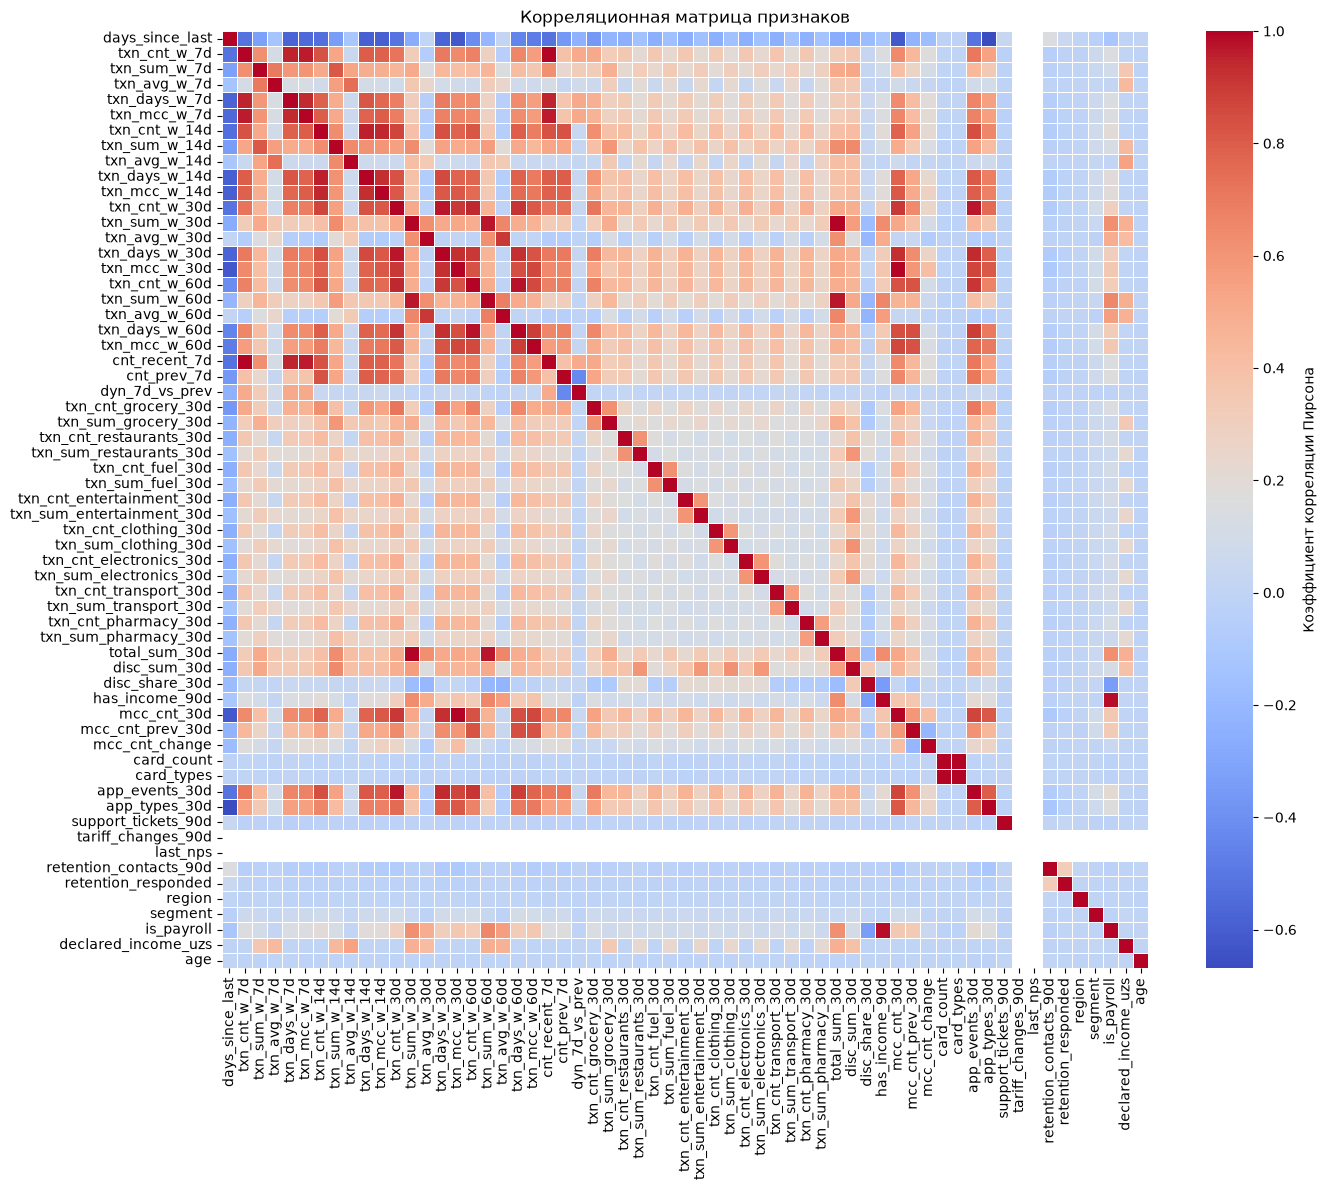

Найдено 29 пар с |корреляцией| > 0.9:
  txn_cnt_w_7d <-> txn_days_w_7d : 0.948
  txn_cnt_w_7d <-> txn_mcc_w_7d : 0.966
  txn_cnt_w_7d <-> cnt_recent_7d : 1.000
  txn_days_w_7d <-> txn_mcc_w_7d : 0.938
  txn_days_w_7d <-> cnt_recent_7d : 0.948
  txn_mcc_w_7d <-> cnt_recent_7d : 0.966
  txn_cnt_w_14d <-> txn_days_w_14d : 0.960
  txn_cnt_w_14d <-> txn_mcc_w_14d : 0.942
  txn_days_w_14d <-> txn_mcc_w_14d : 0.934
  txn_cnt_w_30d <-> txn_days_w_30d : 0.971
  txn_cnt_w_30d <-> txn_mcc_w_30d : 0.908
  txn_cnt_w_30d <-> txn_cnt_w_60d : 0.944
  txn_cnt_w_30d <-> txn_days_w_60d : 0.921
  txn_cnt_w_30d <-> mcc_cnt_30d : 0.908
  txn_cnt_w_30d <-> app_events_30d : 0.969
  txn_sum_w_30d <-> txn_sum_w_60d : 0.969
  txn_sum_w_30d <-> total_sum_30d : 1.000
  txn_avg_w_30d <-> txn_avg_w_60d : 0.904
  txn_days_w_30d <-> txn_mcc_w_30d : 0.924
  txn_days_w_30d <-> txn_cnt_w_60d : 0.908
  txn_days_w_30d <-> txn_days_w_60d : 0.925
  txn_days_w_30d <-> mcc_cnt_30d : 0.924
  txn_days_w_30d <-> app_events_30d : 

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr

# 1. Вычисляем корреляционную матрицу для всех числовых признаков
# (убедимся, что все колонки числовые; у нас они уже такие)
corr_matrix = X_train.corr()

# 2. Визуализация тепловой карты
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5, 
            cbar_kws={'label': 'Коэффициент корреляции Пирсона'})
plt.title('Корреляционная матрица признаков')
plt.tight_layout()
plt.show()

# 3. Находим пары с высокой корреляцией (|r| > threshold)
threshold = 0.9
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

if high_corr_pairs:
    print(f"Найдено {len(high_corr_pairs)} пар с |корреляцией| > {threshold}:")
    for feat1, feat2, corr in high_corr_pairs:
        print(f"  {feat1} <-> {feat2} : {corr:.3f}")
else:
    print(f"Нет пар с |корреляцией| > {threshold}")

# 4. Используем важность признаков из модели для принятия решения об удалении
# Получим importance из модели (уже есть)
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': model.feature_importances_
})

# Для каждой пары с высокой корреляцией решаем, какой признак удалить
# Критерий: удаляем признак с меньшей важностью
to_drop = set()
for feat1, feat2, corr in high_corr_pairs:
    imp1 = importance_df[importance_df['feature'] == feat1]['importance'].values[0]
    imp2 = importance_df[importance_df['feature'] == feat2]['importance'].values[0]
    if imp1 < imp2:
        to_drop.add(feat1)
    else:
        to_drop.add(feat2)

print(f"\nРекомендуемые признаки для удаления (из-за высокой корреляции):")
print(list(to_drop))

# 5. (Опционально) Создаём новую матрицу признаков без этих колонок
if to_drop:
    X_train_reduced = X_train.drop(columns=list(to_drop))
    X_val_reduced = X_val.drop(columns=list(to_drop))
    X_test_reduced = X_test.drop(columns=list(to_drop))
    print(f"Размерность X_train после удаления: {X_train_reduced.shape}")
else:
    X_train_reduced = X_train.copy()
    X_val_reduced = X_val.copy()
    X_test_reduced = X_test.copy()
    print("Никакие признаки не удалены.")

## Шаг 1. Определить отток

Сколько дней без активности считать уходом, на какую дату вы смотрите (snapshot)
и на какой горизонт вперёд предсказываете.

Обоснуйте цифры, а не берите первые попавшиеся. Полезно посмотреть, как реально
распределяются паузы между операциями у ваших клиентов: если половина спокойно
делает перерывы на 40 дней, то порог в 30 дней объявит оттоком половину базы.

In [ ]:
# Ваш анализ пауз между операциями и выбор определения


## Шаг 2. Собрать базу для обучения

Не каждый клиент попадает в выборку. Подумайте, что делать с теми, кто:

- и так уже давно молчит на дату snapshot (они ушли раньше, предсказывать нечего);
- зарегистрировался неделю назад (истории для фичей нет);
- попал в конец выгрузки, и окно наблюдения по нему ещё не закрылось.

Каждое решение зафиксируйте: кого исключили и почему.

In [ ]:
# Ваша база: customer_id, snapshot_date, target


## Шаг 3. Понять, что произошло

Посчитайте отток по месяцам. Он действительно вырос? Когда именно?
Найдите в данных событие, которое это объясняет, и проверьте, все ли клиенты
пострадали одинаково или только часть.

In [ ]:
# Динамика оттока по месяцам и разрез по сегментам


## Шаг 4. Фичи

Всё считается строго до даты snapshot.

Смотрите не только на уровень активности, но и на её динамику: сравните последние
недели с предыдущими. Полезно подумать про поведение в приложении, обращения
в поддержку, подписки и продукты, глубину отношений с банком.

Отдельно про сезонность: в данных есть месяцы с естественным спадом активности.
Проверьте, что ваша фича «активность упала» не измеряет просто лето.

In [ ]:
# Ваши фичи


## Шаг 5. Модель и честная проверка

Обучение на одном срезе, проверка на следующем (out-of-time), а не случайным сплитом.
Посмотрите на важность фичей и объясните, почему им можно верить.

In [ ]:
# Модель, метрики, важность фичей


## Шаг 6. Ответ бизнесу

Удержание стоит денег: скидка, бонус, звонок оператора. Кому и сколько предлагать,
если бюджета хватает не на всех? Покажите, где ваша модель окупается, а где нет.

## Что вы показываете

Защита состоит из двух частей, обе в одной презентации.

**Часть 1. Таргет.** Определение оттока и логика за ним: почему такой порог тишины,
такой snapshot и такой горизонт. Как собрали базу и кого исключили. Доля оттока,
её динамика по месяцам и что в данных объясняет рост.

**Часть 2. ML-модель.** Фичи и почему им можно верить. Как разбивали на обучение
и проверку. Метрики и что они значат для бизнеса. Кого модель ставит в топ риска
и что с ними делать.

## Как сдавать

Решайте в этом ноутбуке. Ответы впишите в форму задания на платформе,
ноутбук прикрепите там же кнопкой «Прикрепить ноутбук», презентацию приложите
ссылкой или файлом.